In [161]:
import numpy as np
import pandas as pd
import matplotlib as mpl
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px
import plotly.graph_objects as go

In [162]:
# load data into df

df = pd.read_csv("../data/processed/pharma_sales_data_string_cleaned.csv", encoding="utf-8", na_values=["", "NA", "-", "?"])

In [163]:
# 1.  What are the total sales quantities for each drug category (ATC code)?
drugs = [c for c in df.columns if df[c].dtype == "float64"]
total_sales = df[drugs].sum().reset_index()
total_sales

,index,0
0,m01ab,10600.937083
1,m01ae,8204.618646
2,n02ba,8172.209000
3,n02be,63005.402708
4,n05b,18645.737500
5,n05c,1249.958333
6,r03,11608.822917
7,r06,6107.817500


c:\Users\shank\anaconda3\Lib\site-packages\seaborn\_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):
c:\Users\shank\anaconda3\Lib\site-packages\seaborn\_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):


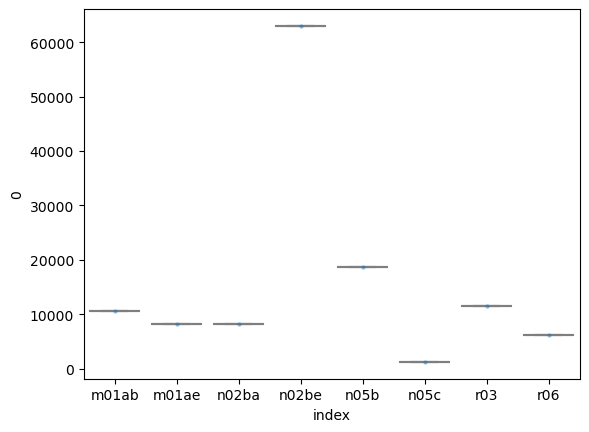

In [164]:
# data viz of result
ax = sns.boxplot(data=total_sales, x="index", y=0, color="lightgrey", showfliers=False)
sns.stripplot(data=total_sales, x="index", y=0, size=3, alpha=0.5, ax=ax)
plt.show()


In [165]:
# 2. Which individual drug brands have the highest total sales?
total_sales = total_sales.reset_index()
total_sales.sort_values(by=0,ascending=False).iloc[0]

level_0               3
index             n02be
0          63005.402708
Name: 3, dtype: object

In [166]:
# 3. Which three drugs have the highest sales in January 2015, July 2016, September 2017

# function to find highest sales , helper function
def highest_sales(df, drugs, n):
    total = df[drugs].sum().reset_index()
    return total.sort_values(by=0, ascending=False).iloc[0:n]

# a. jan 2015
mask_2015 = df["year"] == 2015
mask_jan = df["month"] == 6
jan_2015 = df[(mask_2015) & (mask_jan)]
print("3 highest sales in jan 2015")
jan_2015_top_3 = highest_sales(jan_2015, drugs, 3)
jan_2015_top_3["month"] = ["Jan 2015"]*3
display(jan_2015_top_3)

# b. july 2016
mask_2016 = df["year"] == 2016
mask_june = df["month"] == 6
jan_2016 = df[(mask_2016) & (mask_june)]
print("3 hghest sales in june 2016")
jan_2016_top_3 = highest_sales(jan_2016, drugs, 3)
jan_2016_top_3["month"] = ["Jan 2016"]*3
display(jan_2016_top_3)

# b. September 2017
mask_2017 = df["year"] == 2017
mask_september = df["month"] == 9
september_2017 = df[(mask_2017) & (mask_september)]
print("3 hghest sales in September 2017")
september_2017_top_3 = highest_sales(september_2017, drugs, 3)
september_2017_top_3["month"] = ["September 2017"]*3
display(september_2017_top_3)


3 highest sales in jan 2015


,index,0,month
3,n02be,715.413,Jan 2015
4,n05b,217.000,Jan 2015
6,r03,193.000,Jan 2015


3 hghest sales in june 2016


,index,0,month
3,n02be,760.05,Jan 2016
4,n05b,280.50,Jan 2016
0,m01ab,169.67,Jan 2016


3 hghest sales in September 2017


,index,0,month
3,n02be,863.75,September 2017
4,n05b,223.00,September 2017
6,r03,139.00,September 2017


c:\Users\shank\anaconda3\Lib\site-packages\seaborn\categorical.py:3201: UserWarning: Setting `sharex=False` with `color=None` may cause different levels of the `x` variable to share colors. This will change in a future version.
  warnings.warn(msg.format("sharex", "x"), UserWarning)


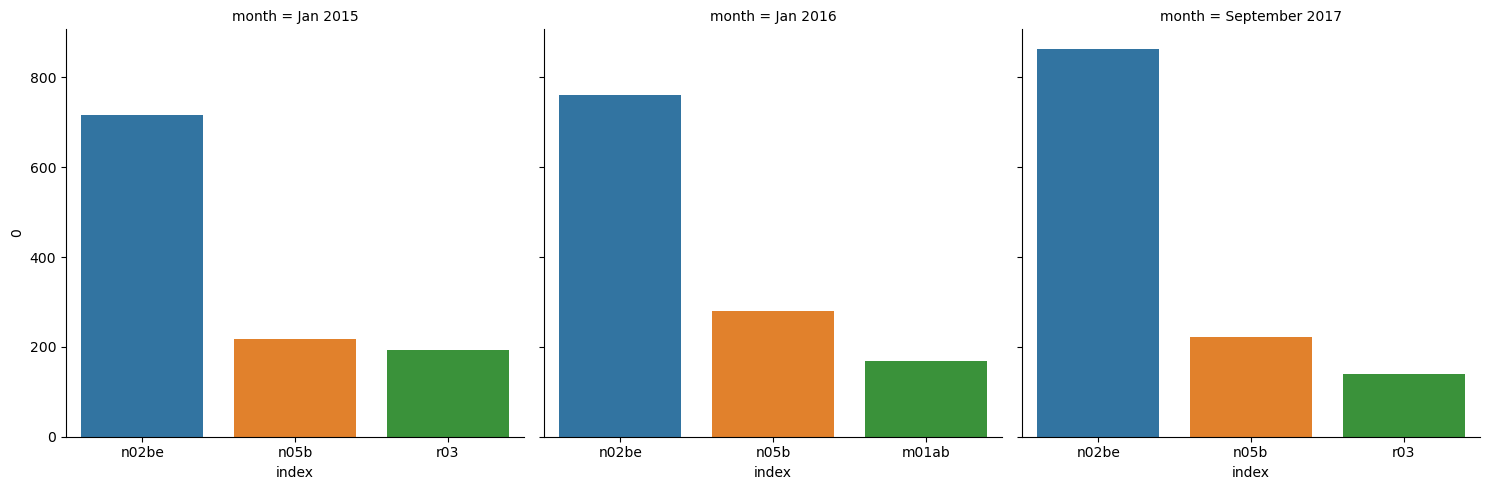

In [167]:
#combine all 3 
combined_months_df = pd.concat([jan_2015_top_3, jan_2016_top_3, september_2017_top_3])
sns.catplot(data=combined_months_df, x="index", y=0, col="month", kind="bar", sharex=False)

In [168]:
# Which drug has sold the most often in 2017?
highest_sales(df[mask_2017], drugs, 1)


,index,0
3,n02be,9258.804833


In [169]:
# Which drug category has the highest average daily sales?
avg_sales = df[drugs].mean()
avg_sales = avg_sales.reset_index()
avg_sales.sort_values(by=0,ascending=False).iloc[0]

index        n02be
0        29.917095
Name: 3, dtype: object

In [170]:
# Are respiratory drugs (R03) sold more during specific months?

# strategy = group by month and aggregate it by total and then pick the highest
df.groupby("month")["r03"].agg("sum").reset_index().sort_values(by="r03",ascending=False)

# answer = Jan

,month,r03
0,1,1264.656250
11,12,1227.000000
9,10,1175.000000
2,3,1170.000000
1,2,1165.583333
3,4,1038.875000
10,11,934.000000
4,5,931.291667
8,9,792.416667
5,6,783.000000


c:\Users\shank\anaconda3\Lib\site-packages\seaborn\_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):
c:\Users\shank\anaconda3\Lib\site-packages\seaborn\_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):


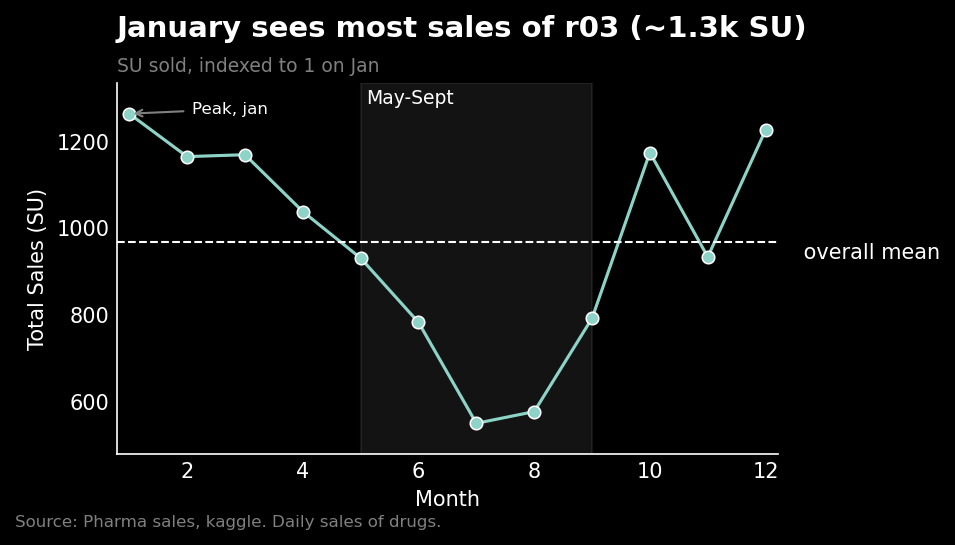

In [ ]:
# data viz to see the trend
respiratory_drugs = df.groupby("month")["r03"].agg("sum").reset_index().sort_values(by="r03",ascending=False)
jan_sales = round(respiratory_drugs.iloc[0]["r03"], 1)
jan_sales_index = respiratory_drugs["r03"].idxmax()
mean_sales_r03 = respiratory_drugs["r03"].mean()

with plt.style.context("dark_background"):
    fig, ax = plt.subplots(figsize=(6.4, 3.6), dpi=150)
    pal = sns.color_palette("colorblind", 4)
    sns.lineplot(data = respiratory_drugs, x = "month", y = "r03", marker="o", ax=ax)

    #may -  sept
    ax.axvspan(5, 9, color="grey", alpha=0.15)
    ax.text(5.1 , ax.get_ylim()[1], "May-Sept", va="center", fontsize=9)

    ax.axhline(mean_sales_r03, color="white", ls="--", lw=1)
    ax.text(ax.get_xlim()[1], mean_sales_r03, " overall mean", va="top")


    #annotate
    ax.annotate("Peak, jan", xy=(respiratory_drugs["month"][jan_sales_index], respiratory_drugs["r03"][jan_sales_index]), xytext=(30, 0), 
                textcoords="offset points", arrowprops={"arrowstyle": "->", "color": "grey"}, fontsize=8) # xytext says 30 points to the right and 0 points upwards
    fig.text(0.01, 0.01, "Source: Pharma sales, kaggle. Daily sales of drugs.", ha="left", fontsize=8, color="grey")
    fig.subplots_adjust(bottom=0.15)
    lo, hi = respiratory_drugs["r03"].min(), respiratory_drugs["r03"].max()
    pad = (hi-lo) * 0.1
    ax.set_ylim(lo-pad, hi+pad)

    sns.despine()

    #axis margins
    ax.margins(x=0.02, y=0.15)

    #declutter
    ax.locator_params(axis="y", nbins=5)
    ax.tick_params(length=0)

    ax.set_xlabel("Month")
    ax.set_ylabel("Total Sales (SU)")
    ax.set_title(f"January sees most sales of r03 (~{jan_sales / 1e3:.1f}k SU)", loc="left", fontsize=14, fontweight="bold", pad=22)
    ax.text(0, 1.03, "SU sold, indexed to 1 on Jan", transform=ax.transAxes, color="grey", fontsize=9)

    fig.tight_layout() #tight layout so full plot will be saved and nothing will be cropped out
    fig.savefig("../reports/figures/r03_max_sales_month.png", facecolor=fig.get_facecolor())

In [172]:
# January is the month with highest sales of r03 drug